# Spambase Spam Classification

Five classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) trained on the same split of the [UCI Spambase](https://archive.ics.uci.edu/dataset/94/spambase) data and compared on Accuracy, AUC, Precision, Recall, F1 and MCC. Target: `is_spam` (1 = spam).

## 1. Setup

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 2026          # one seed drives the split, the CV folds and the stochastic models
TEST_SIZE = 0.20
DATA_DIR = Path("data")

## 2. Load data

Feature names are read from `spambase.names`. Six names with special characters (`;`, `(`, `[`, `!`, `$`, `#`) are renamed to words.

In [2]:
CHAR_NAMES = {";": "semicolon", "(": "paren", "[": "bracket",
              "!": "exclamation", "$": "dollar", "#": "hash"}

def read_feature_names(names_file):
    names = []
    for line in Path(names_file).read_text().splitlines():
        m = re.match(r"^(\S+):\s+continuous\.", line)
        if m:
            name = m.group(1)
            if name.startswith("char_freq_"):
                name = "char_freq_" + CHAR_NAMES[name[len("char_freq_"):]]
            names.append(name)
    return names

feature_names = read_feature_names(DATA_DIR / "spambase.names")
raw = pd.read_csv(DATA_DIR / "spambase.data", header=None,
                  names=feature_names + ["is_spam"])

print(f"Raw shape: {raw.shape[0]} rows x {raw.shape[1]} columns "
      f"({len(feature_names)} features + 1 target)")
raw.head()

Raw shape: 4601 rows x 58 columns (57 features + 1 target)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_paren,char_freq_bracket,char_freq_exclamation,char_freq_dollar,char_freq_hash,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## 3. Data checks and EDA

### 3.1 Missing values and duplicates

In [3]:
print("Missing values      :", int(raw.isna().sum().sum()))
print("Non-numeric columns :", int((~raw.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()))
print("Exact duplicate rows:", int(raw.duplicated().sum()))

Missing values      : 0
Non-numeric columns : 0
Exact duplicate rows: 391


No missing values and all columns are numeric, but there are exact duplicate rows. They are dropped so no e-mail appears in both train and test.

In [4]:
df = raw.drop_duplicates().reset_index(drop=True)
print(f"After removing duplicates: {df.shape[0]} rows x {df.shape[1]} columns")

# Assignment requirement check: >= 12 features and >= 500 instances
assert len(feature_names) >= 12 and len(df) >= 500
print(f"Requirement check passed: {len(feature_names)} features (>=12), {len(df)} instances (>=500)")

After removing duplicates: 4210 rows x 58 columns
Requirement check passed: 57 features (>=12), 4210 instances (>=500)


### 3.2 Class balance

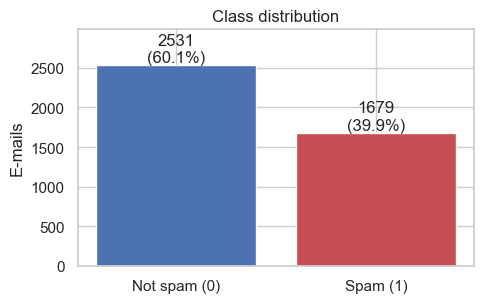

In [5]:
counts = df["is_spam"].value_counts().sort_index()
labels = {0: "Not spam (0)", 1: "Spam (1)"}

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar([labels[i] for i in counts.index], counts.values,
              color=["#4C72B0", "#C44E52"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / len(df):.1%})",
            ha="center", va="bottom")
ax.set_ylabel("E-mails")
ax.set_title("Class distribution")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout()
plt.show()

Moderate imbalance, so accuracy alone is not enough. Precision, recall, F1 and MCC are reported too.

### 3.3 Feature distributions

Most features are zero for most e-mails and heavily right-skewed.

Top 8 most skewed features:
char_freq_hash                31.5
capital_run_length_longest    31.2
word_freq_3d                  27.2
word_freq_parts               27.1
capital_run_length_average    22.8
char_freq_bracket             21.3
word_freq_table               19.3
word_freq_conference          18.9

Features with skewness > 2: 56 of 57


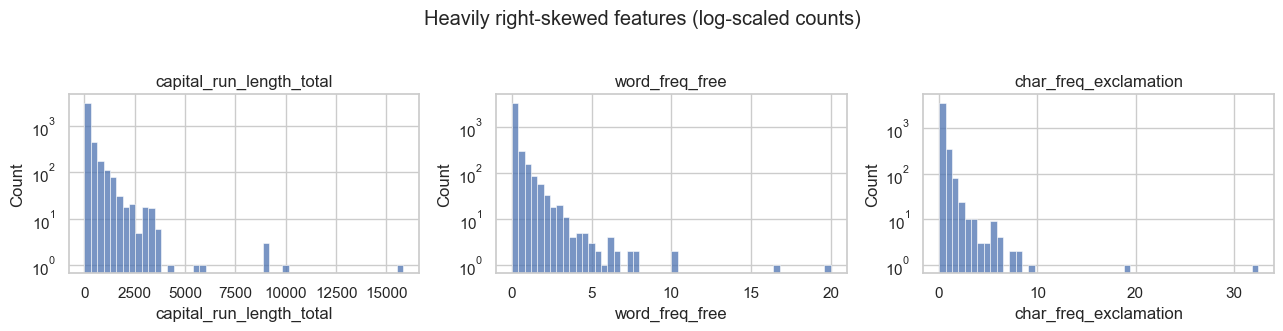

In [6]:
X_all = df[feature_names]
skew = X_all.skew().sort_values(ascending=False)
print("Top 8 most skewed features:")
print(skew.head(8).round(1).to_string())
print(f"\nFeatures with skewness > 2: {(skew > 2).sum()} of {len(skew)}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, ["capital_run_length_total", "word_freq_free", "char_freq_exclamation"]):
    sns.histplot(df[col], bins=50, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_yscale("log")
plt.suptitle("Heavily right-skewed features (log-scaled counts)", y=1.03)
plt.tight_layout()
plt.show()

Because almost every feature is skewed, Logistic Regression, KNN and SVM use `log(1 + x)` plus standardisation, and Naive Bayes uses `log(1 + x)` only. The Decision Tree is unaffected by monotonic transforms, so it gets raw features.

### 3.4 Features with the largest class gap

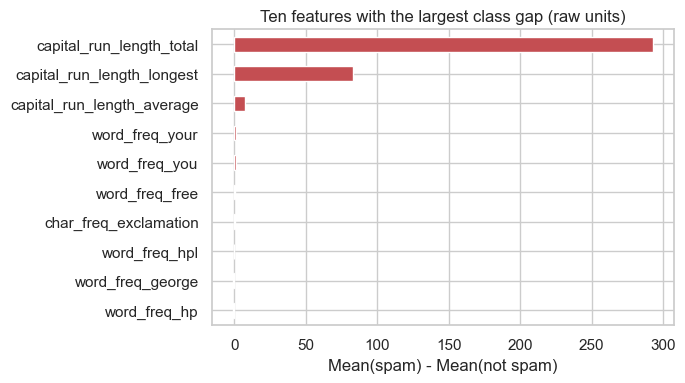

In [7]:
gap = (df.groupby("is_spam")[feature_names].mean().T
         .rename(columns={0: "mean_not_spam", 1: "mean_spam"}))
gap["spam_minus_ham"] = gap["mean_spam"] - gap["mean_not_spam"]
top = gap.reindex(gap["spam_minus_ham"].abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(7, 4))
top["spam_minus_ham"].sort_values().plot.barh(
    ax=ax, color=["#C44E52" if v > 0 else "#4C72B0" for v in top["spam_minus_ham"].sort_values()])
ax.set_xlabel("Mean(spam) - Mean(not spam)")
ax.set_title("Ten features with the largest class gap (raw units)")
plt.tight_layout()
plt.show()

## 4. Train/test split

Stratified 80/20. The test set is used only for the final evaluation. Tuning uses cross-validation on the training set.

In [8]:
X = df[feature_names]
y = df["is_spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "spam share": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
summary["spam share"] = summary["spam share"].map("{:.2%}".format)
summary

,rows,spam share
train,3368,39.88%
test,842,39.90%


## 5. Models and hyperparameter search

Each model is a `Pipeline`, so preprocessing is fitted on training data only. Tuning is a 5-fold stratified `GridSearchCV` on ROC AUC.

| Model | Preprocessing | Tuned |
|-------|---------------|-------|
| Logistic Regression | log, scale | `C` |
| Decision Tree | none | `max_depth`, `min_samples_leaf` |
| KNN | log, scale | `n_neighbors`, `weights` |
| Naive Bayes | log | `var_smoothing` |
| SVM (RBF) | log, scale | `C`, `gamma` |

In [9]:
def log_scale():
    # log(1 + x) is safe here because every Spambase feature is >= 0
    return [("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler())]

search_space = {
    "Logistic Regression": (
        Pipeline(log_scale() + [("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100, 1000]},
    ),
    "Decision Tree": (
        Pipeline([("clf", DecisionTreeClassifier(random_state=SEED))]),
        {"clf__max_depth": [4, 6, 8, 12, None],
         "clf__min_samples_leaf": [1, 5, 10, 20, 40, 80]},
    ),
    "KNN": (
        Pipeline(log_scale() + [("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [3, 5, 7, 11, 15, 21],
         "clf__weights": ["uniform", "distance"]},
    ),
    "Naive Bayes": (
        Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                  ("clf", GaussianNB())]),
        {"clf__var_smoothing": [1e-9, 1e-6, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]},
    ),
    "SVM": (
        Pipeline(log_scale() + [("clf", SVC(kernel="rbf", probability=True, random_state=SEED))]),
        {"clf__C": [1, 10, 100, 1000],
         "clf__gamma": ["scale", 0.001, 0.003, 0.01, 0.03]},
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [10]:
fitted = {}
tuning_rows = []

for name, (pipe, grid) in search_space.items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    fitted[name] = gs.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best parameters": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
        "CV AUC (5-fold, train only)": round(gs.best_score_, 4),
    })

pd.DataFrame(tuning_rows).set_index("Model")

,Best parameters,"CV AUC (5-fold, train only)"
Model,,
Logistic Regression,{'C': 100},0.9803
Decision Tree,"{'max_depth': None, 'min_samples_leaf': 40}",0.9494
KNN,"{'n_neighbors': 15, 'weights': 'distance'}",0.9764
Naive Bayes,{'var_smoothing': 0.01},0.9616
SVM,"{'C': 100, 'gamma': 0.003}",0.9833


## 6. Evaluation on the test set

Positive class = spam (`1`). AUC uses predicted probabilities.

In [11]:
def evaluate(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "AUC": roc_auc_score(y_eval, y_prob),
        "Precision": precision_score(y_eval, y_pred, pos_label=1),
        "Recall": recall_score(y_eval, y_pred, pos_label=1),
        "F1": f1_score(y_eval, y_pred, pos_label=1),
        "MCC": matthews_corrcoef(y_eval, y_pred),
    }

results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in fitted.items()}).T
results.index.name = "ML Model Name"
results = results.round(4)

(results.style
    .format("{:.4f}")
    .background_gradient(cmap="YlGn", axis=0)
    .set_caption("Test-set performance (best value per metric is darkest)"))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9264,0.9733,0.9308,0.8810,0.9052,0.8459
Decision Tree,0.8979,0.9611,0.9195,0.8155,0.8644,0.7865
KNN,0.9299,0.9738,0.9342,0.8869,0.9099,0.8534
Naive Bayes,0.8527,0.9657,0.7454,0.9583,0.8385,0.7259
SVM,0.9371,0.9795,0.9464,0.8929,0.9188,0.8685


### 6.1 Metric comparison

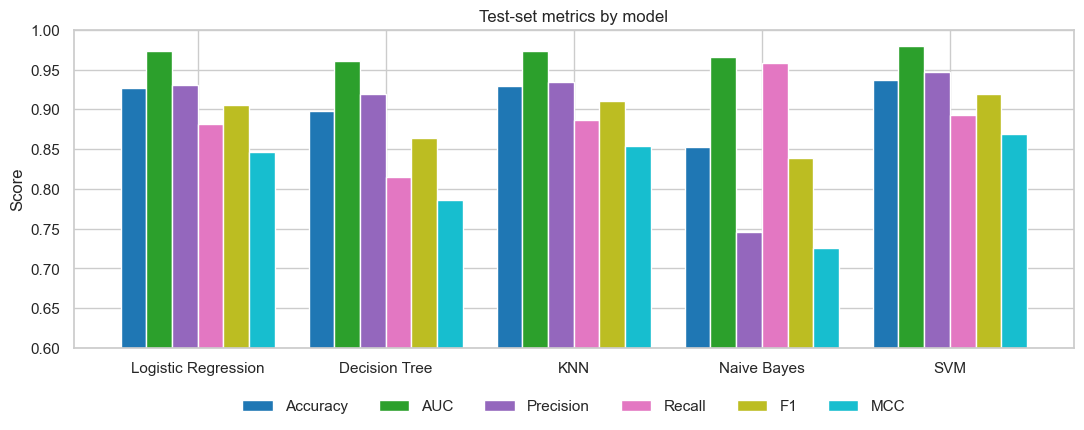

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.5))
results.plot.bar(ax=ax, width=0.82, colormap="tab10", edgecolor="white")
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_title("Test-set metrics by model")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.2 Confusion matrices

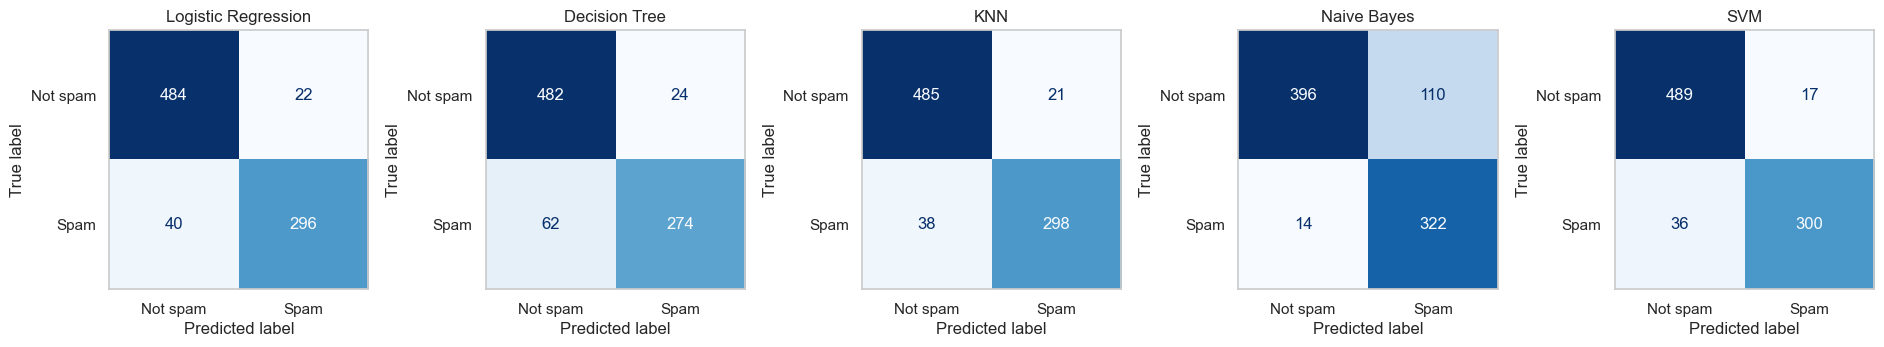

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["Not spam", "Spam"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

### 6.3 ROC curves

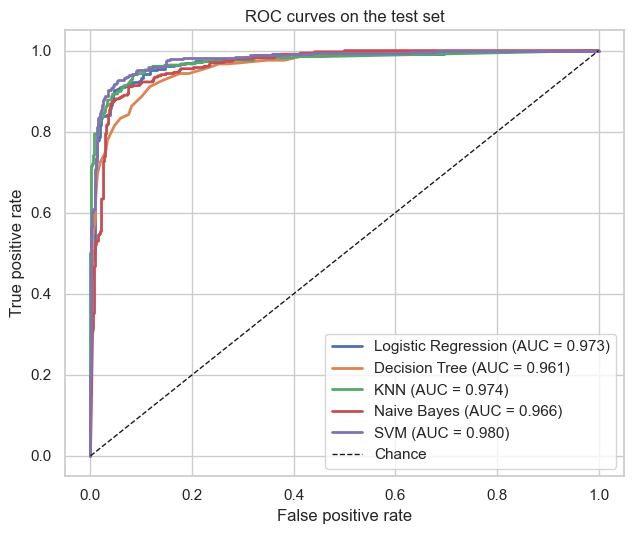

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, model in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {results.loc[name, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 6.4 Ranking

In [15]:
ranks = results.rank(ascending=False, method="min").astype(int)
ranks["Mean rank"] = ranks.mean(axis=1).round(2)
ranks.sort_values("Mean rank")

,Accuracy,AUC,Precision,Recall,F1,MCC,Mean rank
ML Model Name,,,,,,,
SVM,1,1,1,2,1,1,1.17
KNN,2,2,2,3,2,2,2.17
Logistic Regression,3,3,3,4,3,3,3.17
Naive Bayes,5,4,5,1,5,5,4.17
Decision Tree,4,5,4,5,4,4,4.33


## 7. Observations

*Results for `SEED = 2026`; exact figures may shift slightly with another seed.*

| Model | Observation |
|-------|-------------|
| Logistic Regression | Strong linear baseline (accuracy 0.926, MCC 0.846). Best with weak regularisation (`C` = 100). |
| Decision Tree | Lowest AUC (0.961) and recall (0.816). Missed 62 spam e-mails, the most of any model. |
| KNN | Slightly ahead of Logistic Regression (accuracy 0.930, MCC 0.853). Relies on the log and scaling steps. |
| Naive Bayes | Highest recall (0.958) but lowest precision (0.745): 110 legitimate e-mails flagged. Lowest accuracy and MCC (0.726). |
| SVM | Best accuracy, AUC, precision, F1 and MCC. Fewest false alarms (17). |

**Winner: SVM (RBF)**. It leads on five of six metrics and has the best mean rank.

## 8. Save models and test data

Saves each pipeline to `model/` and the test split to `test_data.csv` for the Streamlit app.

In [16]:
import joblib

MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib",
}

for name, model in fitted.items():
    joblib.dump(model, MODEL_DIR / MODEL_FILES[name], compress=3)

test_df = X_test.copy()
test_df["is_spam"] = y_test.values
test_df.to_csv("test_data.csv", index=False)

print("Saved models:")
for f in sorted(MODEL_DIR.glob("*.joblib")):
    print(f"  {f}  ({f.stat().st_size / 1024:.0f} KB)")
print(f"\nSaved test_data.csv: {test_df.shape[0]} rows x {test_df.shape[1]} columns")

Saved models:
  model/decision_tree.joblib  (4 KB)
  model/knn.joblib  (388 KB)
  model/logistic_regression.joblib  (3 KB)
  model/naive_bayes.joblib  (3 KB)
  model/svm.joblib  (65 KB)

Saved test_data.csv: 842 rows x 58 columns


### Round-trip check

Reloaded models must reproduce the results table above.

In [17]:
test_reloaded = pd.read_csv("test_data.csv")
Xr, yr = test_reloaded.drop(columns="is_spam"), test_reloaded["is_spam"]

reloaded = {name: joblib.load(MODEL_DIR / fname) for name, fname in MODEL_FILES.items()}
check = pd.DataFrame({name: evaluate(m, Xr, yr) for name, m in reloaded.items()}).T.round(4)

assert check.equals(results[check.columns]), "Reloaded models do not match the in-memory results"
print("Round-trip check passed: reloaded models reproduce the table in section 6.")

Round-trip check passed: reloaded models reproduce the table in section 6.
